# Pronóstico del número de ocupados en las 13 ciudades principales

Este cuaderno compara regresiones lineales con tendencia y estacionalidad, promedios móviles y configuraciones de suavización exponencial para pronosticar la serie mensual `Ocupados`, expresada en **miles de personas**. La selección se basa en una división cronológica simple entre entrenamiento y los últimos seis meses de prueba.

**Importante sobre las fechas:** el archivo `datosEmpleo.xlsx` disponible en este ejercicio termina en junio de 2019. Por ello, el pronóstico de seis meses generado aquí corresponde a **julio-diciembre de 2019**.

## 1. Paquetes y carga de datos

Se carga la hoja `Hoja1`, se usa `mes` como índice mensual y se valida que las fechas sean únicas y que `Ocupados` no tenga datos faltantes. La columna `Ocupados` se convierte a número y se redondea a tres decimales al cargarla, para ajustarse a la precisión del Excel. No se imputan valores faltantes de forma silenciosa.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import shapiro
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.stats.stattools import jarque_bera, durbin_watson
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.stattools import adfuller, kpss

plt.style.use("seaborn-v0_8-whitegrid")


In [2]:
possible_paths = [
    Path("datosEmpleo.xlsx"),
    Path("Cuadernos Jupyter sesión 1-20261110") / "datosEmpleo.xlsx",
]
data_path = next((path for path in possible_paths if path.is_file()), None)
if data_path is None:
    searched = "\n".join(f"- {path.resolve()}" for path in possible_paths)
    raise FileNotFoundError(
        "No se encontró datosEmpleo.xlsx. Coloca el archivo junto al cuaderno "
        f"o en la carpeta esperada. Rutas revisadas:\n{searched}"
    )

data = pd.read_excel(data_path, sheet_name="Hoja1", parse_dates=["mes"])
required_columns = {"mes", "Ocupados"}
missing_columns = required_columns.difference(data.columns)
if missing_columns:
    raise ValueError(f"Faltan columnas requeridas en el Excel: {sorted(missing_columns)}")

data = data[["mes", "Ocupados"]].copy()
data["Ocupados"] = pd.to_numeric(data["Ocupados"], errors="raise").round(3)
data = data.sort_values("mes").set_index("mes")
if data.index.has_duplicates:
    raise ValueError("La columna mes contiene fechas duplicadas; revísalas antes del análisis.")

# Normaliza las fechas al inicio de cada mes y establece frecuencia mensual explícita.
data.index = data.index.to_period("M").to_timestamp()
data = data.asfreq("MS")
print(f"Archivo: {data_path.resolve()}")
print(f"Observaciones: {len(data)} | período: {data.index.min():%Y-%m} a {data.index.max():%Y-%m}")
display(data.head())
display(data.tail())

Archivo: /Users/veroserna1/Github repositories/Aprendizaje_Autom_3/datosEmpleo.xlsx
Observaciones: 222 | período: 2001-01 a 2019-06


,Ocupados
mes,
2001-01-01,6923.604
2001-02-01,7037.746
2001-03-01,6945.973
2001-04-01,6973.079
2001-05-01,6994.462


,Ocupados
mes,
2019-02-01,10557.917
2019-03-01,10760.776
2019-04-01,10632.028
2019-05-01,10813.000
2019-06-01,10848.000


## 2. Exploración básica

Se revisan estructura, faltantes, valores descriptivos y trayectoria temporal. La unidad de la variable se conserva como miles de personas.

Dimensiones: (222, 1)
Tipos de datos:
 Ocupados    float64
dtype: object
Valores faltantes:
 Ocupados    0
dtype: int64


,Ocupados (miles)
count,222.000000
mean,9160.852009
std,1295.492800
min,6923.604000
25%,7971.103000
50%,9139.064500
75%,10458.510250
max,11037.199000


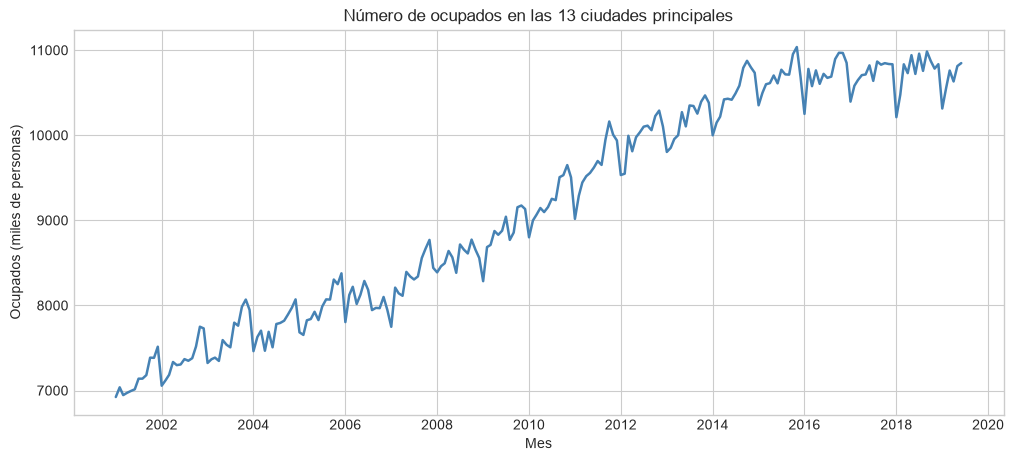

In [3]:
print("Dimensiones:", data.shape)
print("Tipos de datos:\n", data.dtypes)
print("Valores faltantes:\n", data.isna().sum())
display(data["Ocupados"].describe().to_frame("Ocupados (miles)"))

if data["Ocupados"].isna().any():
    missing_months = data.index[data["Ocupados"].isna()].strftime("%Y-%m").tolist()
    raise ValueError(
        "Hay meses sin dato de Ocupados después de establecer la frecuencia mensual: "
        f"{missing_months}. Completa o corrige la fuente antes de modelar."
    )
if len(data) < 48:
    raise ValueError("Se requieren al menos 48 meses para separar seis meses de prueba y ajustar modelos estacionales anuales.")

y = data["Ocupados"].astype(float)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index, y, color="steelblue", linewidth=1.8)
ax.set(title="Número de ocupados en las 13 ciudades principales", xlabel="Mes", ylabel="Ocupados (miles de personas)")
plt.show()

## 3. Estrategia de evaluación

Para evitar elegir configuraciones usando el conjunto de prueba, se separan los **últimos seis meses observados** como prueba final, que no participa en el ajuste ni en la selección. Los datos anteriores (desarrollo) se usan para comparar candidatos en seis bloques cronológicos de validación, cada uno de seis meses. En cada bloque, el modelo se ajusta solo con observaciones anteriores al bloque y pronostica sus seis meses siguientes.

Se selecciona la configuración con menor RMSE promedio entre los seis bloques de validación; MAE y sMAPE complementan la comparación, y se reporta la variabilidad del RMSE entre bloques. Solo después de seleccionar el modelo, se evalúa una vez contra los seis meses finales reservados. Los promedios móviles se pronostican recursivamente, incorporando cada estimación a la ventana siguiente. Esta validación temporal repetida es más informativa que escoger y reportar el ganador en el mismo bloque.

In [6]:
HORIZON = 6 # periodo de pronóstico en meses
SEASONAL_PERIODS = 12 # periodo estacional en meses

if len(y) <= 7 * HORIZON:
    raise ValueError("La serie es demasiado corta para conservar prueba final y seis bloques de validación.")

train_eval = y.iloc[:-HORIZON]
test_eval = y.iloc[-HORIZON:]
validation_origins = list(range(len(train_eval) - 6 * HORIZON, len(train_eval), HORIZON))
validation_folds = [
    (train_eval.iloc[:origin], train_eval.iloc[origin:origin + HORIZON])
    for origin in validation_origins
]

print(f"Horizonte de cada pronóstico: {HORIZON} meses")
print(f"Desarrollo para validación: {train_eval.index[0]:%Y-%m} a {train_eval.index[-1]:%Y-%m} ({len(train_eval)} meses)")
for fold_number, (train_fold, validation_fold) in enumerate(validation_folds, start=1):
    print(f"Validación {fold_number}: entrenamiento hasta {train_fold.index[-1]:%Y-%m}; "
          f"validación {validation_fold.index[0]:%Y-%m} a {validation_fold.index[-1]:%Y-%m}")
print(f"Prueba final reservada: {test_eval.index[0]:%Y-%m} a {test_eval.index[-1]:%Y-%m} ({len(test_eval)} meses)")

Horizonte de cada pronóstico: 6 meses
Desarrollo para validación: 2001-01 a 2018-12 (216 meses)
Validación 1: entrenamiento hasta 2015-12; validación 2016-01 a 2016-06
Validación 2: entrenamiento hasta 2016-06; validación 2016-07 a 2016-12
Validación 3: entrenamiento hasta 2016-12; validación 2017-01 a 2017-06
Validación 4: entrenamiento hasta 2017-06; validación 2017-07 a 2017-12
Validación 5: entrenamiento hasta 2017-12; validación 2018-01 a 2018-06
Validación 6: entrenamiento hasta 2018-06; validación 2018-07 a 2018-12
Prueba final reservada: 2019-01 a 2019-06 (6 meses)


## 4. Modelos candidatos

- **Regresión lineal:** tendencias lineal, cuadrática y cúbica; cada forma se evalúa con y sin estacionalidad mensual. 
- **Promedios móviles:** ventanas de 2 a 12 meses, tanto con pesos iguales como con pesos lineales crecientes para dar mayor peso a los datos recientes.
- **Suavización exponencial mediante ETS:** se comparan configuraciones con y sin tendencia, con estacionalidad aditiva o multiplicativa cuando corresponde. Para configuraciones estacionales se usa un ciclo de 12 meses.

Para suavizar datos observados, `rolling(window).mean()` calcula el promedio móvil en cada fecha. Para pronosticar una fecha futura, el código usa `shift(1).rolling(...)`: desplaza los datos conocidos para que el promedio quede alineado con el mes que se quiere estimar, sin incluir un valor real de ese mes. En pronósticos de varios meses, cada predicción se agrega al historial y se usa para calcular la siguiente.

En las medias ponderadas se usan pesos 1, 2, ..., ventana, normalizados para sumar uno. Todos los candidatos se comparan en los mismos bloques de validación; los seis meses de prueba final permanecen fuera de la selección.

En las salidas ETS se muestran únicamente los parámetros de suavización: **α (alfa)** ajusta el nivel de la serie y determina cuánto influyen los datos recientes; **β (beta)** ajusta la tendencia; y **γ (gamma)** ajusta el patrón estacional. Un valor más alto da más peso a los cambios recientes y uno más bajo suaviza más. Si un modelo no incluye tendencia o estacionalidad, β o γ aparece como «No aplica».

In [4]:
def moving_average_forecast(train, window, horizon, weighted=False):
    """Pronostica recursivamente; shift().rolling() alinea el promedio pasado con cada mes futuro."""
    history = train.astype(float).copy()
    predictions = []

    for _ in range(horizon):
        next_month = history.index[-1] + pd.DateOffset(months=1)
        # Añade el mes a pronosticar; shift(1) coloca en él solo los valores ya conocidos.
        extended_history = pd.concat([history, pd.Series([np.nan], index=[next_month])])
        shifted = extended_history.shift(1)
        if weighted:
            weights = np.arange(1, window + 1, dtype=float)
            moving_average = shifted.rolling(window=window, min_periods=window).apply(
                lambda values: np.average(values, weights=weights), raw=True
            )
        else:
            moving_average = shifted.rolling(window=window, min_periods=window).mean()
        next_value = float(moving_average.loc[next_month])
        predictions.append(next_value)

        # Incorpora el pronóstico para poder calcular el siguiente mes futuro.
        history.loc[next_month] = next_value

    return np.asarray(predictions)


def linear_regression_forecast(train, horizon, trend_form, include_seasonality):
    train = train.astype(float)
    train_time = np.arange(len(train), dtype=float)

    def design_matrix(index, time_values):
        years = time_values / 12
        if trend_form == "lineal":
            features = pd.DataFrame({"t": years}, index=index)
        elif trend_form == "cuadrática":
            features = pd.DataFrame({"t": years, "t2": years ** 2}, index=index)
        elif trend_form == "cúbica":
            features = pd.DataFrame(
                {"t": years, "t2": years ** 2, "t3": years ** 3}, index=index
            )
        else:
            raise ValueError(f"Forma de tendencia desconocida: {trend_form}")
        if include_seasonality:
            for month in range(2, 13):
                features[f"mes_{month}"] = (index.month == month).astype(float)
        return sm.add_constant(features, has_constant="add")

    x_train = design_matrix(train.index, train_time)
    fitted = sm.OLS(train, x_train).fit()
    future_index = pd.date_range(
        start=train.index[-1], periods=horizon + 1, freq="MS"
    )[1:]
    future_time = np.arange(len(train), len(train) + horizon, dtype=float)
    predictions = fitted.predict(design_matrix(future_index, future_time))
    return fitted, predictions


def forecast_model(model_name, train, horizon, verbose=False):
    """Ajusta una configuración candidata usando solo `train` y devuelve el horizonte solicitado."""
    if model_name.startswith("Promedio móvil"):
        weighted = "ponderado" in model_name
        window = int(model_name.rsplit(" ", 1)[-1])
        return moving_average_forecast(train, window, horizon, weighted)

    if model_name.startswith("Regresión "):
        include_seasonality = "y estacionalidad" in model_name
        if model_name.startswith("Regresión lineal"):
            trend_form = "lineal"
        elif model_name.startswith("Regresión cúbica"):
            trend_form = "cúbica"
        elif model_name.startswith("Regresión cuadrática"):
            trend_form = "cuadrática"
        else:
            raise ValueError(f"Configuración de regresión desconocida: {model_name}")
        _, predictions = linear_regression_forecast(
            train, horizon, trend_form, include_seasonality
        )
        return np.asarray(predictions, dtype=float)

    if model_name == "ETS - error aditivo, sin tendencia":
        fitted = ETSModel(train, error="add").fit(disp=False)
    elif model_name == "ETS - error aditivo, estacionalidad aditiva":
        fitted = ETSModel(
            train, error="add", seasonal="add",
            seasonal_periods=SEASONAL_PERIODS,
        ).fit(disp=False)
    elif model_name == "ETS - error y tendencia multiplicativos":
        if (train <= 0).any():
            raise ValueError("El ETS multiplicativo requiere valores estrictamente positivos.")
        fitted = ETSModel(train, error="mul", trend="mul").fit(disp=False)
    elif model_name == "ETS - error aditivo, tendencia y estacionalidad aditivas":
        fitted = ETSModel(
            train,
            error="add",
            trend="add",
            seasonal="add",
            seasonal_periods=SEASONAL_PERIODS,
        ).fit(disp=False)
    elif model_name == "ETS - error aditivo, estacionalidad multiplicativa":
        if (train <= 0).any():
            raise ValueError("La estacionalidad multiplicativa requiere valores estrictamente positivos.")
        fitted = ETSModel(
            train,
            error="add",
            seasonal="mul",
            seasonal_periods=SEASONAL_PERIODS,
        ).fit(disp=False)
    else:
        raise ValueError(f"Configuración de modelo desconocida: {model_name}")
    alpha = getattr(fitted, "alpha", None)
    beta = getattr(fitted, "beta", None)
    gamma = getattr(fitted, "gamma", None)
    format_parameter = lambda value: f"{value:.3f}" if value is not None else "No aplica"
    predictions = np.asarray(fitted.forecast(horizon), dtype=float)
    if verbose:
        print(
        f"Modelo {model_name} ajustado. Parámetros de suavización: "
        f"α (alfa)={format_parameter(alpha)}, "
        f"β (beta)={format_parameter(beta)}, "
        f"γ (gamma)={format_parameter(gamma)}"
        )
        print(f"Pronóstico de {model_name} para {horizon} meses: {predictions}")
    return predictions


model_names = [
    "Regresión lineal - tendencia",
    "Regresión lineal - tendencia y estacionalidad",
    "Regresión cuadrática - tendencia",
    "Regresión cuadrática - tendencia y estacionalidad",
    "Regresión cúbica - tendencia",
    "Regresión cúbica - tendencia y estacionalidad",
]
model_names.extend(f"Promedio móvil {window}" for window in range(2, 13))
model_names.extend(f"Promedio móvil ponderado {window}" for window in range(2, 13))
model_names.extend([
    "ETS - error aditivo, sin tendencia",
    "ETS - error aditivo, estacionalidad aditiva",
    "ETS - error y tendencia multiplicativos",
    "ETS - error aditivo, tendencia y estacionalidad aditivas",
    "ETS - error aditivo, estacionalidad multiplicativa",
])
if (y <= 0).any():
    model_names.remove("ETS - error y tendencia multiplicativos")
    model_names.remove("ETS - error aditivo, estacionalidad multiplicativa")


### Validaciones previas: estacionariedad débil, estacionalidad y residuos

Antes de comparar pronósticos, se examina la estacionariedad débil en los datos de desarrollo (sin los seis meses reservados para prueba). Se revisan media y desviación estándar móviles de 12 meses y se complementan con ADF (H₀: raíz unitaria) y KPSS (H₀: estacionariedad); las pruebas aportan evidencia, pero no demuestran por sí solas que la serie sea estacionaria. La estacionalidad mensual se contrasta conjuntamente en la regresión lineal con tendencia. También se revisan supuestos de residuos de las regresiones lineales con y sin estacionalidad: autocorrelación, varianza constante y normalidad. Estos diagnósticos orientan la interpretación, pero no sustituyen la comparación predictiva ni se usan para excluir candidatos.

In [ ]:
development_series = train_eval.astype(float)
stationarity_cases = [
    ("Serie en nivel", development_series, "ct", "ct"),
    ("Primera diferencia", development_series.diff().dropna(), "c", "c"),
]
stationarity_rows = []
for label, series, adf_regression, kpss_regression in stationarity_cases:
    adf_result = adfuller(series, regression=adf_regression, autolag="AIC")
    kpss_result = kpss(series, regression=kpss_regression, nlags="auto")
    stationarity_rows.append({
        "Serie": label,
        "ADF p-valor (H0: raíz unitaria)": adf_result[1],
        "KPSS p-valor (H0: estacionaria)": kpss_result[1],
    })
stationarity_results = pd.DataFrame(stationarity_rows)
display(stationarity_results.round(4))

rolling_mean = development_series.rolling(SEASONAL_PERIODS).mean()
rolling_std = development_series.rolling(SEASONAL_PERIODS).std()
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(development_series.index, development_series, alpha=0.55, label="Serie")
axes[0].plot(rolling_mean.index, rolling_mean, color="darkorange", label="Media móvil (12 meses)")
axes[0].set(title="Revisión de la media para estacionariedad débil", ylabel="Ocupados (miles)")
axes[0].legend()
axes[1].plot(rolling_std.index, rolling_std, color="seagreen")
axes[1].set(title="Desviación estándar móvil (12 meses)", xlabel="Mes", ylabel="Desviación estándar")
plt.tight_layout()
plt.show()

linear_without_seasonality, _ = linear_regression_forecast(
    development_series, 1, "lineal", False
)
linear_with_seasonality, _ = linear_regression_forecast(
    development_series, 1, "lineal", True
)
seasonal_columns = [
    column for column in linear_with_seasonality.model.exog_names
    if column.startswith("mes_")
]
seasonality_restrictions = np.zeros((len(seasonal_columns), len(linear_with_seasonality.model.exog_names)))
for row, column in enumerate(seasonal_columns):
    seasonality_restrictions[row, linear_with_seasonality.model.exog_names.index(column)] = 1
seasonality_test = linear_with_seasonality.f_test(seasonality_restrictions)
print(
    "Prueba F conjunta de efectos mensuales, condicionada a tendencia lineal: "
    f"F={float(seasonality_test.fvalue):.3f}, p-valor={float(seasonality_test.pvalue):.4f}"
)
if seasonality_test.pvalue < 0.05:
    print("Hay evidencia de efectos mensuales; se mantiene la variante estacional entre los candidatos.")
else:
    print("No hay evidencia suficiente de efectos mensuales; ambas variantes siguen en la comparación.")

residual_models = {
    "Regresión lineal - tendencia": linear_without_seasonality,
    "Regresión lineal - tendencia y estacionalidad": linear_with_seasonality,
}
residual_rows = []
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (model_name, fitted_model) in enumerate(residual_models.items()):
    residual_values = fitted_model.resid
    ljung_box_result = acorr_ljungbox(residual_values, lags=[12], return_df=True)
    breusch_pagan_result = het_breuschpagan(residual_values, fitted_model.model.exog)
    jarque_bera_result = jarque_bera(residual_values)
    shapiro_result = shapiro(residual_values)
    residual_rows.append({
        "Modelo": model_name,
        "Durbin-Watson": durbin_watson(residual_values),
        "Ljung-Box p-valor (rezago 12)": ljung_box_result["lb_pvalue"].iloc[0],
        "Breusch-Pagan p-valor": breusch_pagan_result[1],
        "Jarque-Bera p-valor": jarque_bera_result[1],
        "Shapiro-Wilk p-valor": shapiro_result.pvalue,
    })
    axes[row, 0].scatter(fitted_model.fittedvalues, residual_values, alpha=0.6)
    axes[row, 0].axhline(0, color="black", linestyle="--")
    axes[row, 0].set(title=f"Residuos vs. ajustados: {model_name}", xlabel="Ajustados", ylabel="Residuos")
    plot_acf(residual_values, lags=36, ax=axes[row, 1])
    axes[row, 1].set_title(f"ACF residuos: {model_name}")
plt.tight_layout()
plt.show()
display(pd.DataFrame(residual_rows).round(4))

## 5. Evaluación y comparación

La configuración se elige con el menor RMSE promedio en los seis bloques de validación. La prueba final no interviene en esta selección y se evalúa únicamente después de fijar al ganador. MAE, sMAPE y la desviación estándar del RMSE entre bloques complementan la comparación. La tabla incluye explícitamente la regresión lineal con tendencia sola y con tendencia más estacionalidad mensual; ambas se conservan como candidatas, y la prueba de estacionalidad previa sirve de contexto, no reemplaza la validación cronológica.

In [7]:
validation_rows = []
for fold_number, (train_fold, validation_fold) in enumerate(validation_folds, start=1):
    actual_values = validation_fold.to_numpy(dtype=float)
    for name in model_names:
        predicted_values = forecast_model(name, train_fold, HORIZON)
        if len(predicted_values) != HORIZON or not np.isfinite(predicted_values).all():
            raise ValueError(f"Pronóstico inválido o desalineado para {name}, bloque {fold_number}.")
        denominator = np.abs(actual_values) + np.abs(predicted_values)
        smape = np.mean(2 * np.abs(actual_values - predicted_values) / denominator) * 100
        validation_rows.append({
            "Bloque": fold_number,
            "Modelo": name,
            "MAE (miles)": mean_absolute_error(actual_values, predicted_values),
            "RMSE (miles)": np.sqrt(mean_squared_error(actual_values, predicted_values)),
            "sMAPE (%)": smape,
        })

validation_results = pd.DataFrame(validation_rows)
validation_scores = (
    validation_results.groupby("Modelo")
    .agg({
        "MAE (miles)": "mean",
        "RMSE (miles)": ["mean", "std"],
        "sMAPE (%)": "mean",
    })
)
validation_scores.columns = ["MAE promedio (miles)", "RMSE promedio (miles)", "Desv. estándar RMSE", "sMAPE promedio (%)"]
validation_scores = validation_scores.sort_values("RMSE promedio (miles)").reset_index()
display(validation_scores.round(3))
linear_comparison = validation_scores[
    validation_scores["Modelo"].isin([
        "Regresión lineal - tendencia",
        "Regresión lineal - tendencia y estacionalidad",
    ])
].copy()
if len(linear_comparison) != 2:
    raise ValueError("La comparación debe incluir regresión lineal con y sin estacionalidad.")
print("Comparación específica de regresión lineal con y sin estacionalidad:")
display(linear_comparison.round(3))
best_model_name = validation_scores.loc[0, "Modelo"]
print(f"Configuración seleccionada por RMSE promedio de validación: {best_model_name}")

# El conjunto final de prueba se usa una sola vez, después de elegir la configuración.
test_actual = test_eval.to_numpy(dtype=float)
test_index = test_eval.index
test_prediction = forecast_model(best_model_name, train_eval, HORIZON)
test_denominator = np.abs(test_actual) + np.abs(test_prediction)
holdout_scores = pd.DataFrame([{
    "Modelo seleccionado": best_model_name,
    "MAE prueba (miles)": mean_absolute_error(test_actual, test_prediction),
    "RMSE prueba (miles)": np.sqrt(mean_squared_error(test_actual, test_prediction)),
    "sMAPE prueba (%)": np.mean(2 * np.abs(test_actual - test_prediction) / test_denominator) * 100,
}])
display(holdout_scores.round(3))
predictions_by_model = {best_model_name: test_prediction}

,Modelo,MAE promedio (miles),RMSE promedio (miles),Desv. estándar RMSE,sMAPE promedio (%)
0,"ETS - error aditivo, estacionalidad aditiva",109.345,125.809,36.137,1.019
1,"ETS - error aditivo, estacionalidad multiplica...",107.241,130.274,52.187,0.996
2,"ETS - error aditivo, tendencia y estacionalida...",139.121,155.708,36.405,1.289
3,Promedio móvil 12,147.348,181.585,46.608,1.377
4,Promedio móvil 11,157.141,195.075,47.066,1.469
5,Promedio móvil ponderado 2,155.032,201.473,90.331,1.447
6,"ETS - error aditivo, sin tendencia",157.678,202.392,86.411,1.472
7,Promedio móvil 10,166.321,204.777,47.347,1.554
8,Promedio móvil ponderado 12,163.849,204.801,55.146,1.530
9,Promedio móvil 2,161.210,206.676,100.116,1.505


Configuración seleccionada por RMSE promedio de validación: ETS - error aditivo, estacionalidad aditiva


,Modelo seleccionado,MAE prueba (miles),RMSE prueba (miles),sMAPE prueba (%)
0,"ETS - error aditivo, estacionalidad aditiva",73.783,84.004,0.693


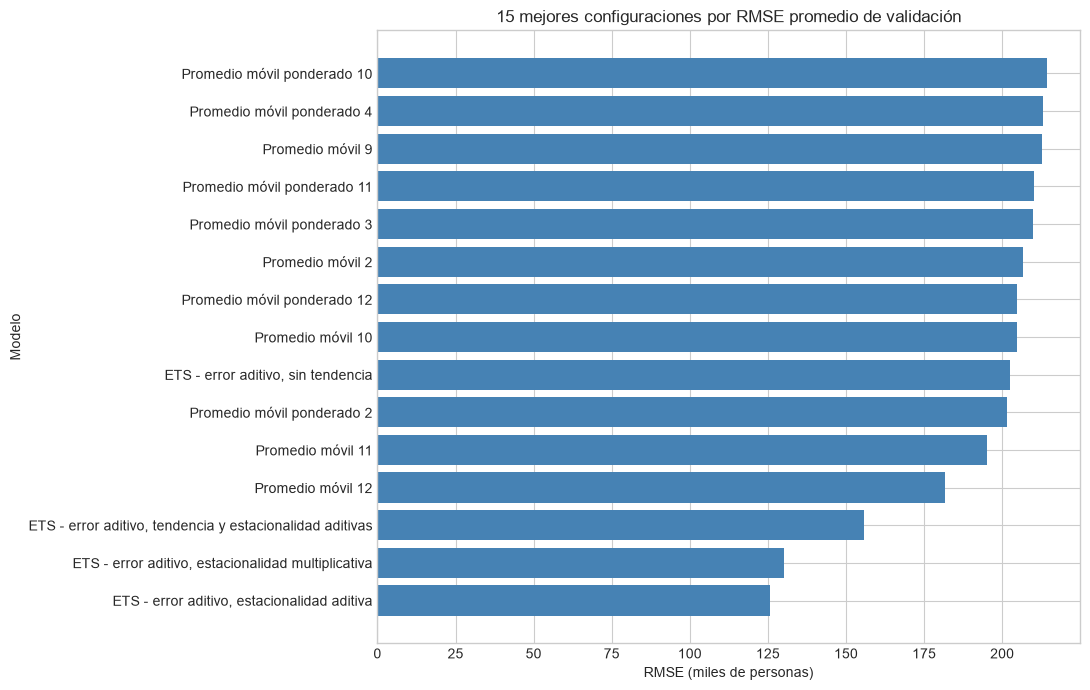

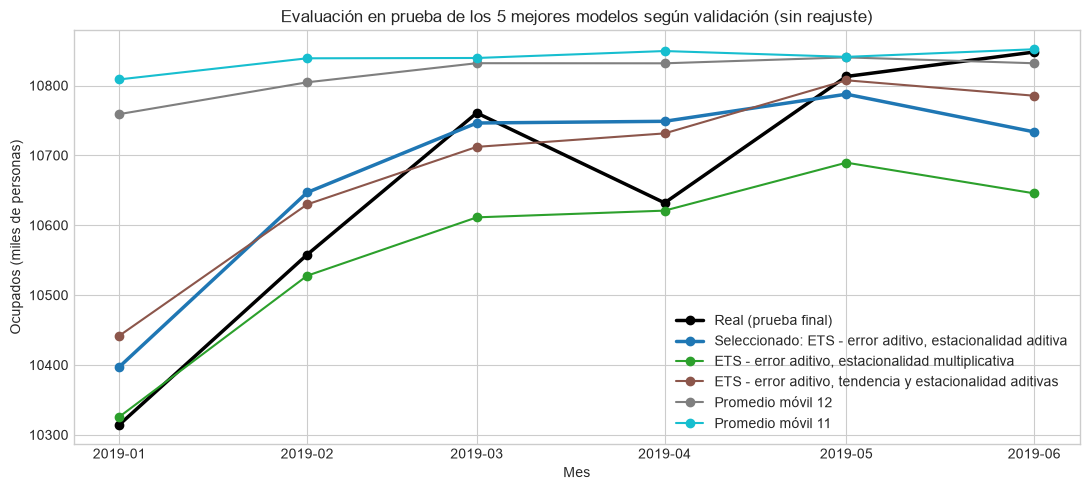

In [7]:
top_models = validation_scores.head(15).sort_values("RMSE promedio (miles)", ascending=True)
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(top_models["Modelo"], top_models["RMSE promedio (miles)"], color="steelblue")
ax.set(title="15 mejores configuraciones por RMSE promedio de validación", xlabel="RMSE (miles de personas)", ylabel="Modelo")
plt.tight_layout()
plt.show()

top_5_models = validation_scores.head(5)["Modelo"].tolist()
predictions_by_model = {
    model_name: forecast_model(model_name, train_eval, HORIZON)
    for model_name in top_5_models
}
test_prediction = predictions_by_model[best_model_name]
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(test_index, test_actual, marker="o", color="black", linewidth=2.5, label="Real (prueba final)")
colors = plt.cm.tab10(np.linspace(0, 1, len(top_5_models)))
for model_name, color in zip(top_5_models, colors):
    ax.plot(
        test_index,
        predictions_by_model[model_name],
        marker="o",
        color=color,
        linewidth=2.5 if model_name == best_model_name else 1.5,
        label=f"Seleccionado: {model_name}" if model_name == best_model_name else model_name,
    )
ax.set(title="Evaluación en prueba de los 5 mejores modelos según validación (sin reajuste)", xlabel="Mes", ylabel="Ocupados (miles de personas)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Diagnóstico de regresión lineal y pronóstico de seis meses

Entre las regresiones, se selecciona la variante con menor RMSE promedio de validación, sin consultar la prueba final. En sus residuos se revisan linealidad y varianza aproximadamente constante con el gráfico de residuos frente a ajustados; normalidad con Q-Q, Jarque-Bera y Shapiro-Wilk; e independencia temporal/ruido blanco con ACF, Durbin-Watson, Ljung-Box y Box-Pierce. Ljung-Box sobre residuos cuadrados explora dependencia en la varianza. Estas pruebas son diagnósticas, no criterios para escoger según la prueba final; p < 0.05 señala evidencia contra la hipótesis nula. Enero es la categoría de referencia estacional.

El ruido blanco es un supuesto diagnóstico importante para los errores de un modelo de serie temporal: en particular, los residuos no deberían conservar autocorrelación. No es por sí solo el criterio de pronóstico ni sustituye las métricas fuera de muestra. Estos diagnósticos corresponden a la mejor regresión según validación y se deben releer al volver a ejecutar el cuaderno.

El mejor modelo global, seleccionado por el menor RMSE promedio de validación, se reajusta con toda la serie disponible para pronosticar los seis meses posteriores a la última observación. El resultado depende de la fecha de corte y de los datos del Excel.

Mejor regresión según RMSE promedio de validación: Regresión cúbica - tendencia y estacionalidad


,Coeficiente,p-valor
const,6979.5553,0.0000
t,-10.7467,0.5861
t2,37.7307,0.0000
t3,-1.4650,0.0000
mes_2,173.7687,0.0007
mes_3,240.2055,0.0000
mes_4,244.4369,0.0000
mes_5,305.6222,0.0000
mes_6,266.1154,0.0000
mes_7,343.0750,0.0000


,Diagnóstico,Resultado
0,Durbin-Watson (independencia),0.750219
1,"Ljung-Box, residuos, rezago 12 (p-valor)",0.0
2,"Ljung-Box, residuos, rezago 24 (p-valor)",0.0
3,"Box-Pierce, residuos, rezago 12 (p-valor)",0.0
4,"Ljung-Box, residuos cuadrados, rezago 12 (p-va...",0.0
5,Breusch-Pagan (p-valor),0.003972
6,Jarque-Bera (p-valor),0.37515
7,Shapiro-Wilk (p-valor),0.323829
8,Ruido blanco (autocorrelación),No cumple: hay autocorrelación residual
9,Varianza constante,No cumple: hay evidencia de varianza no constante


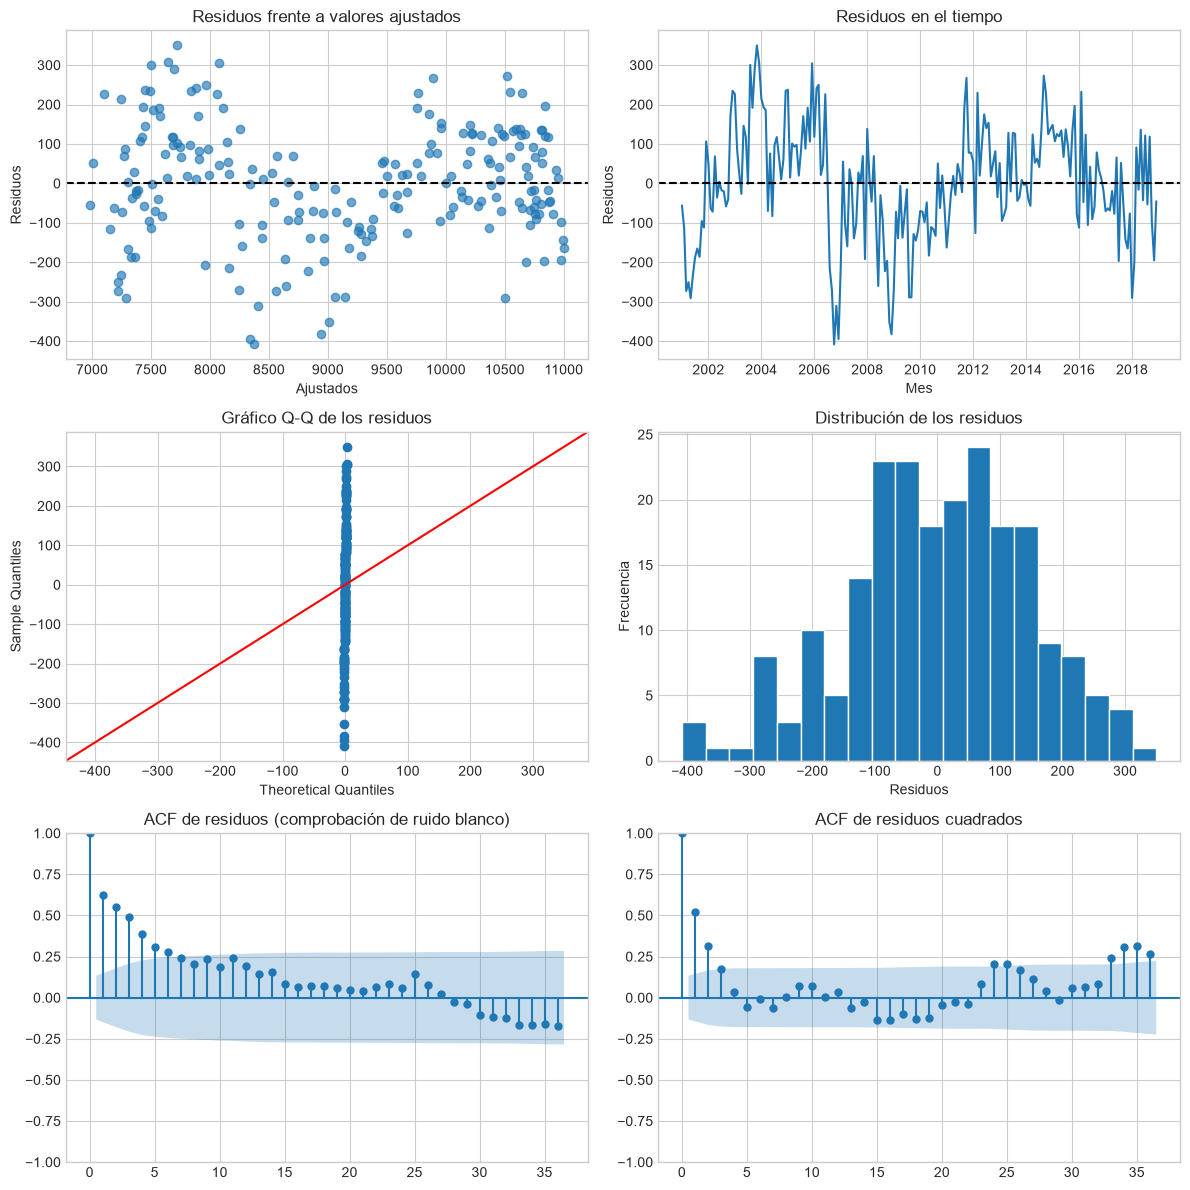

Modelo ETS - error aditivo, estacionalidad aditiva ajustado. Parámetros de suavización: α (alfa)=0.592, β (beta)=No aplica, γ (gamma)=0.000
Pronóstico de ETS - error aditivo, estacionalidad aditiva para 6 meses: [10879.17173379 10853.57191156 10913.08677817 11023.29345628
 11033.28225772 10939.51941016]


,Pronóstico de ocupados (miles),"Pronóstico (personas, aprox.)"
2019-07-01,10879.172,10879172
2019-08-01,10853.572,10853572
2019-09-01,10913.087,10913087
2019-10-01,11023.293,11023293
2019-11-01,11033.282,11033282
2019-12-01,10939.519,10939519


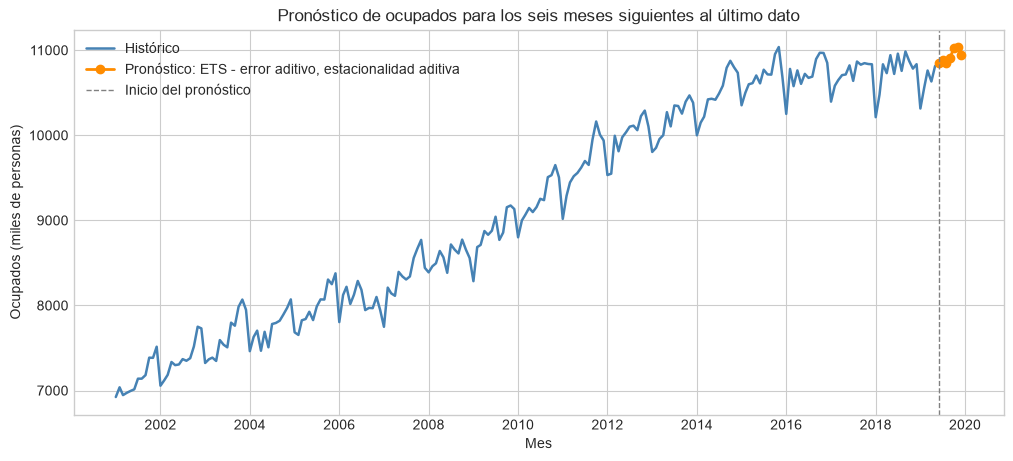

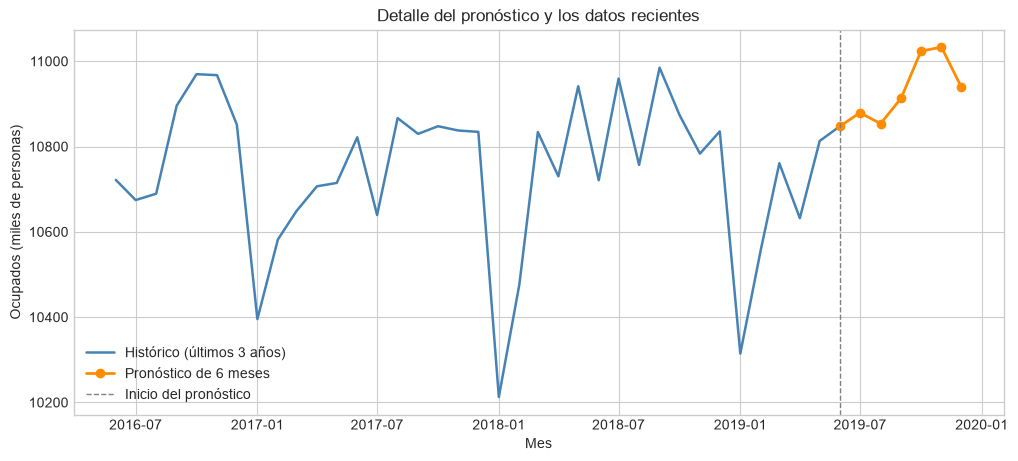

Último dato observado: 2019-06 = 10,848.000 miles de personas
Horizonte pronosticado: 2019-07 a 2019-12
Mejor configuración seleccionada en validación: ETS - error aditivo, estacionalidad aditiva


In [9]:
linear_scores = validation_scores[validation_scores["Modelo"].str.startswith("Regresión ")]
if linear_scores.empty:
    raise ValueError("No se encontraron modelos de regresión lineal en la comparación.")
best_linear_model_name = linear_scores.iloc[0]["Modelo"]
include_seasonality = "y estacionalidad" in best_linear_model_name
if best_linear_model_name.startswith("Regresión lineal"):
    linear_trend_form = "lineal"
elif best_linear_model_name.startswith("Regresión cuadrática"):
    linear_trend_form = "cuadrática"
elif best_linear_model_name.startswith("Regresión cúbica"):
    linear_trend_form = "cúbica"
else:
    raise ValueError(f"Configuración de regresión desconocida: {best_linear_model_name}")
linear_diagnostic_model, _ = linear_regression_forecast(
    train_eval, HORIZON, linear_trend_form, include_seasonality
)
residuals = linear_diagnostic_model.resid
ljung_box = acorr_ljungbox(residuals, lags=[12, 24], return_df=True, boxpierce=True)
ljung_box_squared = acorr_ljungbox(residuals ** 2, lags=[12], return_df=True)
breusch_pagan = het_breuschpagan(
    residuals, linear_diagnostic_model.model.exog
)
jarque_bera_result = jarque_bera(residuals)
shapiro_result = shapiro(residuals)

diagnostics = pd.DataFrame({
    "Diagnóstico": [
        "Durbin-Watson (independencia)",
        "Ljung-Box, residuos, rezago 12 (p-valor)",
        "Ljung-Box, residuos, rezago 24 (p-valor)",
        "Box-Pierce, residuos, rezago 12 (p-valor)",
        "Ljung-Box, residuos cuadrados, rezago 12 (p-valor)",
        "Breusch-Pagan (p-valor)",
        "Jarque-Bera (p-valor)",
        "Shapiro-Wilk (p-valor)",
        "Ruido blanco (autocorrelación)",
        "Varianza constante",
    ],
    "Resultado": [
        durbin_watson(residuals),
        ljung_box["lb_pvalue"].iloc[0],
        ljung_box["lb_pvalue"].iloc[1],
        ljung_box["bp_pvalue"].iloc[0],
        ljung_box_squared["lb_pvalue"].iloc[0],
        breusch_pagan[1],
        jarque_bera_result[1],
        shapiro_result.pvalue,
        ("No cumple: hay autocorrelación residual" if (ljung_box["lb_pvalue"] < 0.05).any()
         else "Sin evidencia de autocorrelación residual"),
        ("No cumple: hay evidencia de varianza no constante"
         if ljung_box_squared["lb_pvalue"].iloc[0] < 0.05 or breusch_pagan[1] < 0.05
         else "Sin evidencia de varianza no constante"),
    ],
})
print(f"Mejor regresión según RMSE promedio de validación: {best_linear_model_name}")
display(pd.DataFrame({"Coeficiente": linear_diagnostic_model.params,
                      "p-valor": linear_diagnostic_model.pvalues}).round(4))
display(diagnostics.round(4))

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes[0, 0].scatter(linear_diagnostic_model.fittedvalues, residuals, alpha=0.65)
axes[0, 0].axhline(0, color="black", linestyle="--")
axes[0, 0].set(title="Residuos frente a valores ajustados", xlabel="Ajustados", ylabel="Residuos")
axes[0, 1].plot(train_eval.index, residuals)
axes[0, 1].axhline(0, color="black", linestyle="--")
axes[0, 1].set(title="Residuos en el tiempo", xlabel="Mes", ylabel="Residuos")
sm.qqplot(residuals, line="45", ax=axes[1, 0])
axes[1, 0].set_title("Gráfico Q-Q de los residuos")
axes[1, 1].hist(residuals, bins=20, edgecolor="white")
axes[1, 1].set(title="Distribución de los residuos", xlabel="Residuos", ylabel="Frecuencia")
plot_acf(residuals, lags=36, ax=axes[2, 0])
axes[2, 0].set_title("ACF de residuos (comprobación de ruido blanco)")
plot_acf(residuals ** 2, lags=36, ax=axes[2, 1])
axes[2, 1].set_title("ACF de residuos cuadrados")
plt.tight_layout()
plt.show()

final_forecast_values = forecast_model(best_model_name, y, HORIZON, verbose=True)
future_index = pd.date_range(start=y.index[-1], periods=HORIZON + 1, freq="MS")[1:]
forecast = pd.Series(final_forecast_values, index=future_index, name="Pronóstico de ocupados (miles)")
forecast_table = forecast.to_frame()
forecast_table["Pronóstico (personas, aprox.)"] = np.rint(forecast_table[forecast.name] * 1000).astype("int64")
display(forecast_table.round(3))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index, y, label="Histórico", color="steelblue", linewidth=1.8)
forecast_line = pd.concat([y.iloc[-1:], forecast])
ax.plot(forecast_line.index, forecast_line, label=f"Pronóstico: {best_model_name}", color="darkorange", marker="o", linewidth=2)
ax.axvline(y.index[-1], color="gray", linestyle="--", linewidth=1, label="Inicio del pronóstico")
ax.set(title="Pronóstico de ocupados para los seis meses siguientes al último dato", xlabel="Mes", ylabel="Ocupados (miles de personas)")
ax.legend()
plt.show()

recent_start = y.index[-1] - pd.DateOffset(years=3)
recent_history = y.loc[y.index >= recent_start]
recent_forecast_line = pd.concat([recent_history.iloc[-1:], forecast])
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(recent_history.index, recent_history, label="Histórico (últimos 3 años)", color="steelblue", linewidth=1.8)
ax.plot(recent_forecast_line.index, recent_forecast_line, label="Pronóstico de 6 meses", color="darkorange", marker="o", linewidth=2)
ax.axvline(y.index[-1], color="gray", linestyle="--", linewidth=1, label="Inicio del pronóstico")
ax.set(title="Detalle del pronóstico y los datos recientes", xlabel="Mes", ylabel="Ocupados (miles de personas)")
ax.legend()
plt.show()

print(f"Último dato observado: {y.index[-1]:%Y-%m} = {y.iloc[-1]:,.3f} miles de personas")
print(f"Horizonte pronosticado: {forecast.index[0]:%Y-%m} a {forecast.index[-1]:%Y-%m}")
print(f"Mejor configuración seleccionada en validación: {best_model_name}")

## 7. Conclusión y limitaciones

La selección se hace por RMSE promedio en seis bloques cronológicos de validación previos al período final. La prueba final de seis meses se reporta aparte para el modelo ya seleccionado, sin usarla para reajustar la elección. La desviación estándar del RMSE y las métricas MAE y sMAPE ayudan a valorar la estabilidad y el tipo de error; aun así, seis bloques históricos no garantizan el mismo desempeño ante cambios estructurales futuros.

El pronóstico es una extrapolación estadística de la serie histórica, no una garantía. Los modelos incluidos no consideran variables externas (por ejemplo, cambios económicos o metodológicos). Además, la fuente disponible llega solo hasta junio de 2019, así que las fechas pronosticadas son julio-diciembre de 2019. No debe interpretarse como una estimación actual sin actualizar los datos y volver a ejecutar todo el análisis.